# Exploratory analysis: card-transaction category classifier
This notebook explores the raw transaction data before any modelling. Every number quoted is computed here, and the last cell turns them into modelling decisions.

## 1. Setup & load
Load the raw and cleaned frames through `src/preprocessing.py` so the EDA sees exactly what the model will see.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "preprocessing.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.preprocessing import (CAT_COLS, DATA_PATH, FIGURES_DIR, MAJOR_TARGET, MINOR_TO_MAJOR, TARGET,
                               clean, dedupe_transactions, derive_major, load_raw, normalise_merchant, temporal_split)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
# Colour-blind-safe qualitative palette (seaborn "colorblind"): no red/green pairing for categories.
PAL = sns.color_palette("colorblind", 10)
sns.set_theme(style="whitegrid", palette=PAL, font_scale=1.0)
BLUE, ORANGE = PAL[0], PAL[1]

def save(name):
    plt.savefig(FIGURES_DIR / f"eda_{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

raw = load_raw()
df = clean(raw)
print("shape:", df.shape)
print("memory (MB):", round(raw.memory_usage(deep=True).sum() / 1e6, 2))
print(raw.dtypes.to_string())

shape: (8121, 19)
memory (MB): 2.73
transaction_id                   str
ref_id                           str
created_at                       str
member_id                        str
member_name                      str
merchant_id                      str
merchant_name                    str
title                            str
amount_value                 float64
amount_currency                  str
fees                           int64
card_type                        str
card_name                        str
digitalization_type              str
merchant_pan_entry_method        str
pfm_recurring_frequency          str
status                           str
major_category                   str
minor_category                   str


## 2. Missing values & constants
Find nulls and constant columns in the raw data, and check whether the missing merchant names have a single explanation.

In [2]:
nulls = raw.isna().sum().rename("nulls").to_frame()
nulls["pct"] = (nulls["nulls"] / len(raw) * 100).round(2)
display(nulls[nulls["nulls"] > 0])
const = [c for c in raw.columns if raw[c].nunique(dropna=False) == 1]
print("constant columns:", const, {c: raw[c].iloc[0] for c in const})
null_m = raw[raw["merchant_name"].isna()]
print("null merchant_name rows:", len(null_m))
print("their titles:", null_m["title"].value_counts(dropna=False).to_dict())
print("title null overall:", raw["title"].isna().sum())
print("pfm_recurring_frequency raw values:", raw["pfm_recurring_frequency"].value_counts(dropna=False).to_dict())

,nulls,pct
merchant_name,113,1.39
pfm_recurring_frequency,7899,97.27
major_category,123,1.51


constant columns: ['amount_currency', 'card_type'] {'amount_currency': 'EUR', 'card_type': 'lydia-card'}
null merchant_name rows: 113
their titles: {'RETRAIT DAB': 113}
title null overall: 0
pfm_recurring_frequency raw values: {nan: 7899, 'monthly': 222}


**Duplicates audit.** `ref_id` should identify a payment, so fewer unique `ref_id`s than rows hints at repeated records. We test for rows identical on every column except `transaction_id`, and check whether such copies would leak across cross-validation folds.

In [3]:
from sklearn.model_selection import StratifiedKFold
key_cols = [c for c in raw.columns if c != "transaction_id"]
dup_mask = raw.duplicated(subset=key_cols, keep="first")
print("rows duplicated on all columns except transaction_id (extra copies):", int(dup_mask.sum()))
print("ref_id nunique:", raw["ref_id"].nunique(), "| rows:", len(raw))
gs = raw[raw.duplicated(subset=key_cols, keep=False)].groupby(key_cols, dropna=False).size()
print("duplicate group sizes:", gs.value_counts().to_dict())
dd = raw[~dup_mask]
print("after dropping duplicates (keep first): rows =", len(dd), "| ref_id unique:", dd["ref_id"].is_unique)
print("duplicates by label:", df.loc[dup_mask, TARGET].value_counts().to_dict())
df["dup_key"] = raw.groupby(key_cols, dropna=False).ngroup()
tr0, te0 = temporal_split(df)
gsz = tr0.groupby("dup_key").size(); dup_groups = gsz[gsz > 1].index
fold = np.empty(len(tr0), dtype=int)
for k, (_, vi) in enumerate(StratifiedKFold(5, shuffle=True, random_state=42).split(tr0, tr0[TARGET])): fold[vi] = k
tr0 = tr0.assign(fold=fold)
straddle = tr0[tr0["dup_key"].isin(dup_groups)].groupby("dup_key")["fold"].nunique().gt(1).sum()
print(f"duplicate groups inside the training period: {len(dup_groups)} | straddling folds under StratifiedKFold(5, shuffle, rs=42): {straddle}")
print("extra duplicate copies inside the training period:", len(tr0) - tr0["dup_key"].nunique(), "| inside the test period:", len(te0) - te0["dup_key"].nunique())
print("duplicate groups present in both train and test of the temporal split:", len(set(tr0["dup_key"]) & set(te0["dup_key"]) & set(gsz.index.union(te0.groupby("dup_key").size().loc[lambda x: x > 1].index))), "| any row-level overlap of dup_key across split:", len(set(tr0["dup_key"]) & set(te0["dup_key"])))

rows duplicated on all columns except transaction_id (extra copies): 120
ref_id nunique: 8001 | rows: 8121
duplicate group sizes: {2: 120}
after dropping duplicates (keep first): rows = 8001 | ref_id unique: True
duplicates by label: {'supermarkets': 35, 'multimedia': 24, 'restaurants': 22, 'transport_means': 13, 'betting': 7, 'atm': 6, 'tolls_gas_stations': 5, 'others_shopping': 3, 'refund': 3, 'travel_means': 1, 'pharmacies': 1}
duplicate groups inside the training period: 101 | straddling folds under StratifiedKFold(5, shuffle, rs=42): 87
extra duplicate copies inside the training period: 101 | inside the test period: 19
duplicate groups present in both train and test of the temporal split: 0 | any row-level overlap of dup_key across split: 0


**Decision.** The duplicated rows are exact repeats (same `ref_id`, timestamp, merchant, amount), so they are removed before training (keep first). Left in, most duplicate pairs would land in different CV folds and inflate scores by memorisation. The temporal split has no cross-split duplicate leakage (no duplicate group spans train and test), but the test period still holds duplicate copies of its own (counts printed above), which slightly change the weighting of evaluation; deduplicating the test period as well keeps evaluation unweighted by repeats.

In [4]:
# Frame used for FEATURE-DECISION diagnostics: deduplicated, then the training part of the temporal split only.
ddf = dedupe_transactions(clean(raw))
dtrain, dtest = temporal_split(ddf)
print("deduplicated frame:", len(ddf), "| deduplicated training period:", len(dtrain), "| deduplicated test period:", len(dtest), "| test starts:", dtest["created_at"].min())

deduplicated frame: 8001 | deduplicated training period: 6400 | deduplicated test period: 1601 | test starts: 2026-05-24 11:07:07+00:00


**Scope of the diagnostics.** Descriptive sections (nulls, duplicates, class balance, agreement) use the full frame. Feature-selection diagnostics (sections 5 to 7: round amounts, categorical signal, mutual information, hour and weekday) are computed on the deduplicated training period (6,400 rows, printed above); the full frame, including the holdout, was inspected during exploration, so the holdout is not pristine; model and hyper-parameter selection nevertheless used only cross-validation on the training period.

## 3. Targets
Look at class balance of both label levels and verify that major is a strict function of minor and that refunds are fully identified by status and sign.

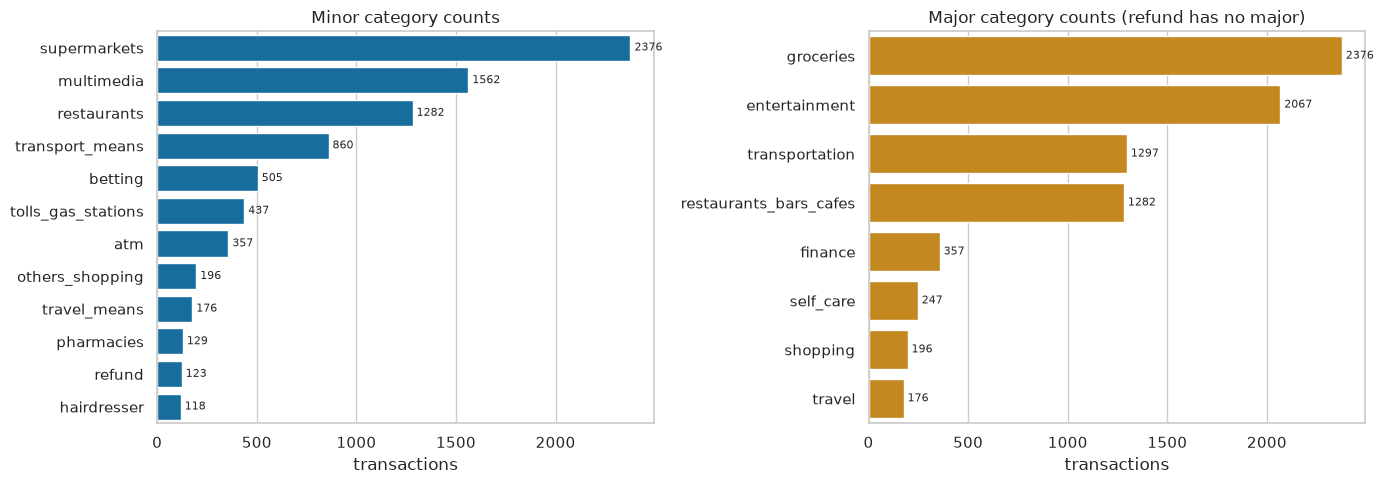

minor classes: 12 | major classes: 8
majority-class share (minor): 0.293 | imbalance ratio max/min: 20.1
rows with null major_category: 123 | their minor classes: ['refund']


major_category,(none),entertainment,finance,groceries,restaurants_bars_cafes,self_care,shopping,transportation,travel
minor_category,,,,,,,,,
atm,0,0,357,0,0,0,0,0,0
betting,0,505,0,0,0,0,0,0,0
hairdresser,0,0,0,0,0,118,0,0,0
multimedia,0,1562,0,0,0,0,0,0,0
others_shopping,0,0,0,0,0,0,196,0,0
pharmacies,0,0,0,0,0,129,0,0,0
refund,123,0,0,0,0,0,0,0,0
restaurants,0,0,0,0,1282,0,0,0,0
supermarkets,0,0,0,2376,0,0,0,0,0


distinct majors per minor (max): 1
minor -> major is a strict function and matches MINOR_TO_MAJOR in src/preprocessing.py
refund rows: 123 | status==refunded: 123 | amount>0: 123
refund <=> status=='refunded' <=> amount_value>0 holds on every row


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
vc = df[TARGET].value_counts()
sns.barplot(x=vc.values, y=vc.index, ax=axes[0], color=BLUE)
axes[0].set(title="Minor category counts", xlabel="transactions", ylabel="")
vm = df[MAJOR_TARGET].value_counts()
sns.barplot(x=vm.values, y=vm.index, ax=axes[1], color=ORANGE)
axes[1].set(title="Major category counts (refund has no major)", xlabel="transactions", ylabel="")
for ax, v in zip(axes, (vc, vm)):
    for i, n in enumerate(v.values): ax.text(n, i, f" {n}", va="center", fontsize=8)
plt.tight_layout(); save("class_balance")
print("minor classes:", df[TARGET].nunique(), "| major classes:", df[MAJOR_TARGET].nunique())
print("majority-class share (minor):", round(vc.iloc[0] / len(df), 3), "| imbalance ratio max/min:", round(vc.iloc[0] / vc.iloc[-1], 1))
print("rows with null major_category:", df[MAJOR_TARGET].isna().sum(), "| their minor classes:", df.loc[df[MAJOR_TARGET].isna(), TARGET].unique().tolist())
ct = pd.crosstab(df[TARGET], df[MAJOR_TARGET].fillna("(none)"))
display(ct)
print("distinct majors per minor (max):", (ct > 0).sum(axis=1).max())
assert (ct > 0).sum(axis=1).eq(1).all(), "minor->major not a function"
_exp = df[TARGET].map(derive_major)
assert (_exp.fillna("(none)") == df[MAJOR_TARGET].fillna("(none)")).all(), "taxonomy disagrees with data"
print("minor -> major is a strict function and matches MINOR_TO_MAJOR in src/preprocessing.py")
is_ref, is_status, is_pos = df[TARGET].eq("refund"), df["status"].eq("refunded"), df["amount_value"] > 0
print("refund rows:", is_ref.sum(), "| status==refunded:", is_status.sum(), "| amount>0:", is_pos.sum())
assert (is_ref == is_status).all() and (is_status == is_pos).all()
print("refund <=> status=='refunded' <=> amount_value>0 holds on every row")

**Transaction-time availability (assumption).** The test's data dictionary lists `status` and `pfm_recurring_frequency` among the fields available at transaction time; refunds appear as separate credit transactions (positive amount, status `refunded`). The refund guard and the recurrence feature are valid only under that contract; if `status` were a later update, the refund class would have to be predicted from text alone. Filling the null recurrence with `none` is likewise an assumption, not documented semantics.

## 4. Merchant text
The title is the strongest candidate feature; measure how noisy it is, how much normalisation collapses it, and how consistently the same normalised title carries the same label (an in-sample agreement diagnostic).

In [6]:
df["text_norm"] = df["title"].map(normalise_merchant)
print("non-null raw merchant_name values:", raw["merchant_name"].nunique(), "(+ empty for the", raw["merchant_name"].isna().sum(), "null rows) | unique raw titles:", df["title"].nunique(), "| unique normalised:", df["text_norm"].nunique())
print("empty normalised titles:", (df["text_norm"] == "").sum())
print("normalise_merchant examples:", {e: normalise_merchant(e) for e in ["MC DONALD'S", "MC DONALD S", "Mc Donalds 1234", "CARREFOUR CITY"]})
spell = df.groupby("text_norm")["title"].agg(lambda s: sorted(set(s)))
merged = spell[spell.str.len() > 1]
print("normalised titles that merge more than one raw spelling:", len(merged), "| raw titles absorbed:", int(merged.str.len().sum() - len(merged)))
display(merged.loc[merged.str.len().sort_values(ascending=False).index[:6]].to_frame("raw spellings merged"))
rest = df[df["text_norm"].str.contains("donald")].groupby("text_norm").size().sort_values(ascending=False)
print("spellings that stay distinct after normalisation (all McDonald's variants):"); print(rest.to_string())
top = {c: g["text_norm"].value_counts().head(10) for c, g in df.groupby(TARGET)}
display(pd.DataFrame({c: [f"{k} ({v})" for k, v in s.items()] + [""] * (10 - len(s)) for c, s in top.items()}))

non-null raw merchant_name values: 959 (+ empty for the 113 null rows) | unique raw titles: 960 | unique normalised: 875
empty normalised titles: 31
normalise_merchant examples: {"MC DONALD'S": 'mc donald s', 'MC DONALD S': 'mc donald s', 'Mc Donalds 1234': 'mc donalds', 'CARREFOUR CITY': 'carrefour city'}
normalised titles that merge more than one raw spelling: 38 | raw titles absorbed: 85


,raw spellings merged
text_norm,
,"[111111100007330, 111111100007370, 11111110000..."
mcdonalds,"[MCDONALDS, MCDONALDS 115, MCDONALDS 1161, MCD..."
yego ride min,"[YEGO* RIDE 10 MIN, YEGO* RIDE 13 MIN, YEGO* R..."
auchan m,"[AUCHAN 0029M, AUCHAN 0030M, AUCHAN 1131M, AUC..."
calao,"[Calao 10, Calao 227, Calao 53]"
google youtube,"[GOOGLE *YouTube, GOOGLE*YOUTUBE, Google YouTube]"


spellings that stay distinct after normalisation (all McDonald's variants):
text_norm
mc donald s          192
mcdonald s            68
mac donald s          56
mcdonalds             40
mc donalds            38
mc donald             14
mc donald s sc        12
mcdonald s dillo       6
resto mc donald s      4
mac donald             4
mc donald s nfc        3
mcdonald s lamen       2
mcdonald s ducos       1
mcdonald s marin       1


,atm,betting,hairdresser,multimedia,others_shopping,pharmacies,refund,restaurants,supermarkets,tolls_gas_stations,transport_means,travel_means
0,retrait dab (109),winamax fr (132),franck provost (33),apple com bill (1048),amazon eu sarl (44),pharmacie (13),apple com bill (16),mc donald s (185),intermarche (324),total (117),ubr pending uber com (138),sncf voyageurs (76)
1,la banque postale (108),betclic (112),barber shop (14),netflix com (109),cdiscount (37),grande pharmacie (9),carrefour city (8),burger king (145),carrefour city (258),autoroutes du s (68),service navigo (119),tcl (30)
2,cash services (81),fdj obgf (59),jean louis david (14),disney plus (68),temu com (26),pharmacie du rer (4),service navigo (5),mcdonald s (65),monoprix (216),escota (42),uber one membership (115),mamp mobilites (17)
3,(30),fdj (54),shop coiffure (8),google one (41),apple com bill (20),pharmacie polygone (3),intermarche (5),mac donald s (54),carrefour market (127),sanef autoroute (16),voi fr (39),tbm vente ligne (5)
4,la societe generale (15),apple com bill (26),barber company (8),paypal itunesappst apple (37),intermarche (6),pharmacie centra (3),disney plus (4),paypal pmntsbveats (53),carrefour (92),cofiroute (14),ratp (27),uber one membership (5)
5,loomis france paris (4),gie pmu (25),rivp (6),wl google (29),netflix com (5),pharmacie de la (3),netflix com (4),mc donalds (38),auchan supermar (91),aprr (12),uber trip (27),sncf ouigo (5)
6,paris guy moque (2),winamax (19),tchip coiffure (6),google summer wallpap (27),monoprix (4),pharmacie evry (3),burger king (4),mcdonalds (36),carrefourmarket (89),carrefour dac vl (12),tisseo open pay (20),trainline sas (3)
7,cabo verde (1),pmu (15),coiffure (5),google google play app (14),carrefour city (4),selarl pharmacie (3),betclic (3),quick (27),lidl (89),aprr nfc (12),uber pending (19),air france (3)
8,cic gme centre ouest (1),pmu internet (12),o barbier (5),canal plus fr (14),auchan supermar (4),pharmacie secret (2),carrefour (3),swile (24),franprix (76),sanef (11),easypark sarl (15),uber trip (3)
9,ccal centre deux (1),bet (4),printemps (4),microsoft subscription (9),noz (4),pharmacie lajava (2),monoprix (3),carte ticket restaurant (19),leclerc (54),station avia (9),mairie de paris (13),trainline (2)


In [7]:
nl = df.groupby("text_norm")[TARGET].nunique()
multi = nl[nl > 1].index
print("normalised merchants with >1 label:", len(multi), "of", len(nl))
print("rows belonging to multi-label merchants:", df["text_norm"].isin(multi).sum(), f"({df['text_norm'].isin(multi).mean():.1%})")
noisy = df[df["text_norm"].isin(multi)].groupby("text_norm").agg(n=(TARGET, "size"), n_labels=(TARGET, "nunique"),
        dist=(TARGET, lambda s: dict(s.value_counts()))).sort_values("n", ascending=False).head(15)
pd.set_option("display.max_colwidth", 120); display(noisy)


def agreement(frame, refund_rule):
    """Share of rows whose label equals the majority label of their normalised title (in-sample).
    With refund_rule the refund rows are assumed solved by the status/sign rule and the majority is taken among non-refunds."""
    base = frame[frame[TARGET] != "refund"] if refund_rule else frame
    ok = base.groupby("text_norm")[TARGET].agg(lambda s: s.value_counts().iloc[0]).sum()
    if refund_rule: ok += (frame[TARGET] == "refund").sum()
    return ok / len(frame), len(frame) - ok
for name, fr, rr in [("raw, all rows", df, False), ("refund-adjusted, all rows", df, True), ("refund-adjusted, deduplicated frame", df[~dup_mask], True)]:
    a, n = agreement(fr, rr); print(f"in-sample normalised-title agreement [{name}]: {a:.4f} | {n} suspected inconsistencies of {len(fr)}")

normalised merchants with >1 label: 145 of 875
rows belonging to multi-label merchants: 5934 (73.1%)


,n,n_labels,dist
text_norm,,,
apple com bill,1110,4,"{'multimedia': 1048, 'betting': 26, 'others_shopping': 20, 'refund': 16}"
intermarche,348,4,"{'supermarkets': 324, 'restaurants': 13, 'others_shopping': 6, 'refund': 5}"
carrefour city,275,4,"{'supermarkets': 258, 'refund': 8, 'restaurants': 5, 'others_shopping': 4}"
monoprix,230,4,"{'supermarkets': 216, 'restaurants': 7, 'others_shopping': 4, 'refund': 3}"
mc donald s,192,3,"{'restaurants': 185, 'transport_means': 5, 'supermarkets': 2}"
burger king,158,4,"{'restaurants': 145, 'transport_means': 6, 'refund': 4, 'supermarkets': 3}"
ubr pending uber com,149,4,"{'transport_means': 138, 'restaurants': 7, 'refund': 2, 'travel_means': 2}"
winamax fr,143,3,"{'betting': 132, 'multimedia': 9, 'refund': 2}"
carrefour market,129,2,"{'supermarkets': 127, 'refund': 2}"


in-sample normalised-title agreement [raw, all rows]: 0.9468 | 432 suspected inconsistencies of 8121


in-sample normalised-title agreement [refund-adjusted, all rows]: 0.9612 | 315 suspected inconsistencies of 8121


in-sample normalised-title agreement [refund-adjusted, deduplicated frame]: 0.9614 | 309 suspected inconsistencies of 8001


**Reading the agreement number.** This is a diagnostic yardstick, not an upper bound: it is in-sample and uses only the title, so a model that also sees amount, entry method or digitalization can legitimately score higher, and a higher test accuracy is not suspicious. The disagreements are suspected inconsistencies (same merchant, different label), not verified labelling errors.

## 5. Amounts
Check whether the amount separates classes, in particular the sign for refunds and round values for ATM withdrawals.

zero-amount rows by class: {'atm': 5}


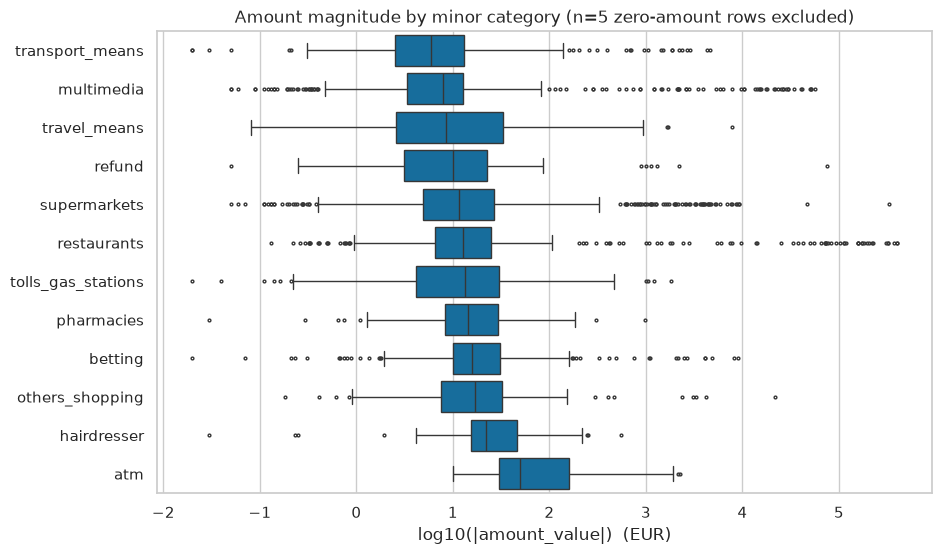

raw amount_value quantiles by sign:


,debits (<0),credits (>0)
0.1%,-222158.92,0.07
1%,-6036.33,0.25
50%,-10.89,10.00
99%,-0.32,1993.29
99.9%,-0.05,67081.39
extreme (min / max),-399180.56,76098.48


,title,minor_category,amount_value,merchant_pan_entry_method
2141,MC DONALD S,restaurants,-399180.56,chip_contactless
7773,VIRAGE,restaurants,-396717.83,chip_contactless
7120,MC DONALD'S,restaurants,-370324.15,chip_contactless
1104,Burger King,supermarkets,-330978.29,chip_contactless
286,BUFFALO GRILL,restaurants,-322254.97,chip_contactless
3157,BUFFALO GRILL,restaurants,-322254.97,chip_contactless
1486,LS SEPT LIEUX,restaurants,-307066.76,chip_contactless
2211,T CHAMPIONS BURGER GIRA 5,restaurants,-226788.68,chip_contactless
5370,PAYPAL *PMNTSBVEATS,restaurants,-222121.58,chip_contactless
2637,MC DONALD S,restaurants,-202562.50,chip_contactless


rows with |amount_value| >= 10,000: 65 | by class: {'restaurants': 36, 'multimedia': 25, 'supermarkets': 2, 'others_shopping': 1, 'refund': 1} | share of rows: 0.008
sign by class (share of rows with amount>0):
minor_category
atm                   0.0
betting               0.0
hairdresser           0.0
multimedia            0.0
others_shopping       0.0
pharmacies            0.0
refund                1.0
restaurants           0.0
supermarkets          0.0
tolls_gas_stations    0.0
transport_means       0.0
travel_means          0.0
positive amounts outside refund: 0
median |amount| by class:
minor_category
transport_means        5.99
multimedia             7.99
travel_means           8.56
refund                10.00
supermarkets          11.66
restaurants           12.76
tolls_gas_stations    13.44
pharmacies            14.44
betting               15.88
others_shopping       16.82
hairdresser           21.81
atm                   50.00
ATM top amounts:
amount_value
20.0     73
50.0    

In [8]:
d = df.copy(); a = d["amount_value"]
zero = d[a == 0]
print("zero-amount rows by class:", zero[TARGET].value_counts().to_dict())
d = d[a != 0].assign(log_abs=lambda x: np.log10(x["amount_value"].abs()))
order = d.groupby(TARGET)["log_abs"].median().sort_values().index
plt.figure(figsize=(10, 6))
sns.boxplot(data=d, y=TARGET, x="log_abs", order=order, color=BLUE, fliersize=2)
plt.title(f"Amount magnitude by minor category (n={len(zero)} zero-amount rows excluded)"); plt.xlabel("log10(|amount_value|)  (EUR)"); plt.ylabel("")
save("amount_by_class")
q = [0.001, 0.01, 0.5, 0.99, 0.999]
qt = pd.DataFrame({"debits (<0)": a[a < 0].quantile(q).tolist() + [a[a < 0].min()], "credits (>0)": a[a > 0].quantile(q).tolist() + [a[a > 0].max()]},
                  index=["0.1%", "1%", "50%", "99%", "99.9%", "extreme (min / max)"])
print("raw amount_value quantiles by sign:"); display(qt.round(2))
display(df.assign(abs_amount=a.abs()).nlargest(10, "abs_amount")[["title", TARGET, "amount_value", "merchant_pan_entry_method"]])
big = a.abs() >= 10000
print("rows with |amount_value| >= 10,000:", int(big.sum()), "| by class:", df.loc[big, TARGET].value_counts().to_dict(), "| share of rows:", round(big.mean(), 4))
print("sign by class (share of rows with amount>0):"); print((a > 0).groupby(df[TARGET]).mean().round(3).to_string())
print("positive amounts outside refund:", ((a > 0) & (df[TARGET] != "refund")).sum())
print("median |amount| by class:"); print(a.abs().groupby(df[TARGET]).median().sort_values().round(2).to_string())
print("ATM top amounts:"); print(a[df[TARGET] == "atm"].abs().value_counts().head(10).to_string())

**Decision.** Amounts are used as log1p(|amount|) with no capping: the extremes above are a handful of rows and look synthetic, so they are disclosed rather than clipped, and the log already tames them. The sign is carried separately (credits are the refund class only).

In [9]:
cents = (dtrain["amount_value"].abs() * 100).round().astype(int)
is_round = (cents > 0) & (cents % 1000 == 0)          # |amount| > 0 and divisible by 10 EUR
print("share of round amounts (|amount|>0 and divisible by 10) per class, deduplicated training period:"); print(is_round.groupby(dtrain[TARGET]).mean().round(3).to_string())
dab = df[df["title"] == "RETRAIT DAB"]
print("label distribution of title == 'RETRAIT DAB':", dab[TARGET].value_counts().to_dict())
display(dab[dab[TARGET] != "atm"][["created_at", "amount_value", "merchant_pan_entry_method", "digitalization_type", "status", TARGET]])
_d = dtrain[dtrain["title"] == "RETRAIT DAB"]
print("RETRAIT DAB labels, deduplicated training period:", _d[TARGET].value_counts().to_dict())
print("ATM rows with title RETRAIT DAB: amounts median/min/max:", dab.loc[dab[TARGET] == "atm", "amount_value"].agg(["median", "min", "max"]).tolist())
print("ATM entry-method mix:", df.loc[df[TARGET] == "atm", "merchant_pan_entry_method"].value_counts().to_dict())

share of round amounts (|amount|>0 and divisible by 10) per class, deduplicated training period:
minor_category
atm                   0.993
betting               0.287
hairdresser           0.087
multimedia            0.002
others_shopping       0.006
pharmacies            0.000
refund                0.032
restaurants           0.001
supermarkets          0.001
tolls_gas_stations    0.006
transport_means       0.013
travel_means          0.000
label distribution of title == 'RETRAIT DAB': {'atm': 109, 'transport_means': 4}


,created_at,amount_value,merchant_pan_entry_method,digitalization_type,status,minor_category
1154,2026-04-21 14:47:44+00:00,-40.0,chip,none,completed,transport_means
1571,2026-03-27 10:03:40+00:00,-100.0,chip,none,completed,transport_means
2043,2026-06-05 15:05:38+00:00,-310.0,chip,none,completed,transport_means
7489,2026-03-19 11:10:09+00:00,-100.0,chip,none,completed,transport_means


RETRAIT DAB labels, deduplicated training period: {'atm': 79, 'transport_means': 3}
ATM rows with title RETRAIT DAB: amounts median/min/max: [-50.0, -2140.0, -0.0]
ATM entry-method mix: {'chip': 345, 'chip_fallback': 7, 'chip_contactless': 5}


**Within-title comparison.** Even a title as clean as `RETRAIT DAB` carries a few non-ATM labels; their amounts and entry methods are listed above and do not obviously differ from the ATM rows, so no claim is made that roundness separates them. A round-amount indicator is kept only as a candidate feature to validate in cross-validation (it is clearly concentrated in the ATM class overall).

## 6. Categorical signal
Feature-selection diagnostics are computed on the deduplicated training period (6,400 rows); the full frame, including the holdout, was inspected during exploration, so the holdout is not pristine; model and hyper-parameter selection nevertheless used only cross-validation on the training period. See which categorical columns carry class information via row-normalised heatmaps and cross-tabs.

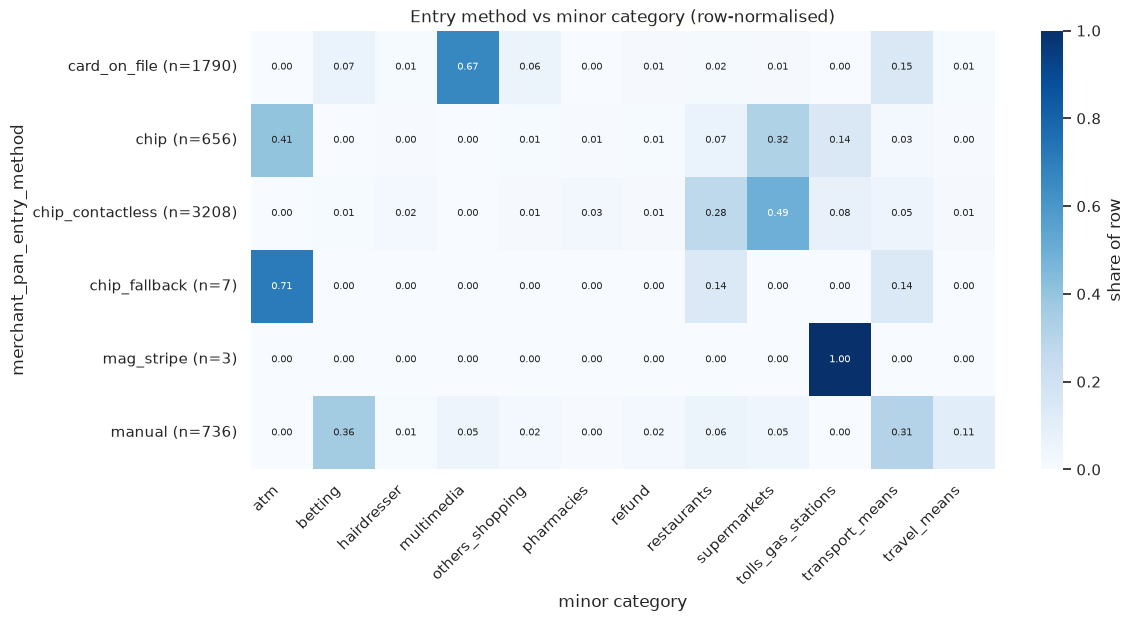

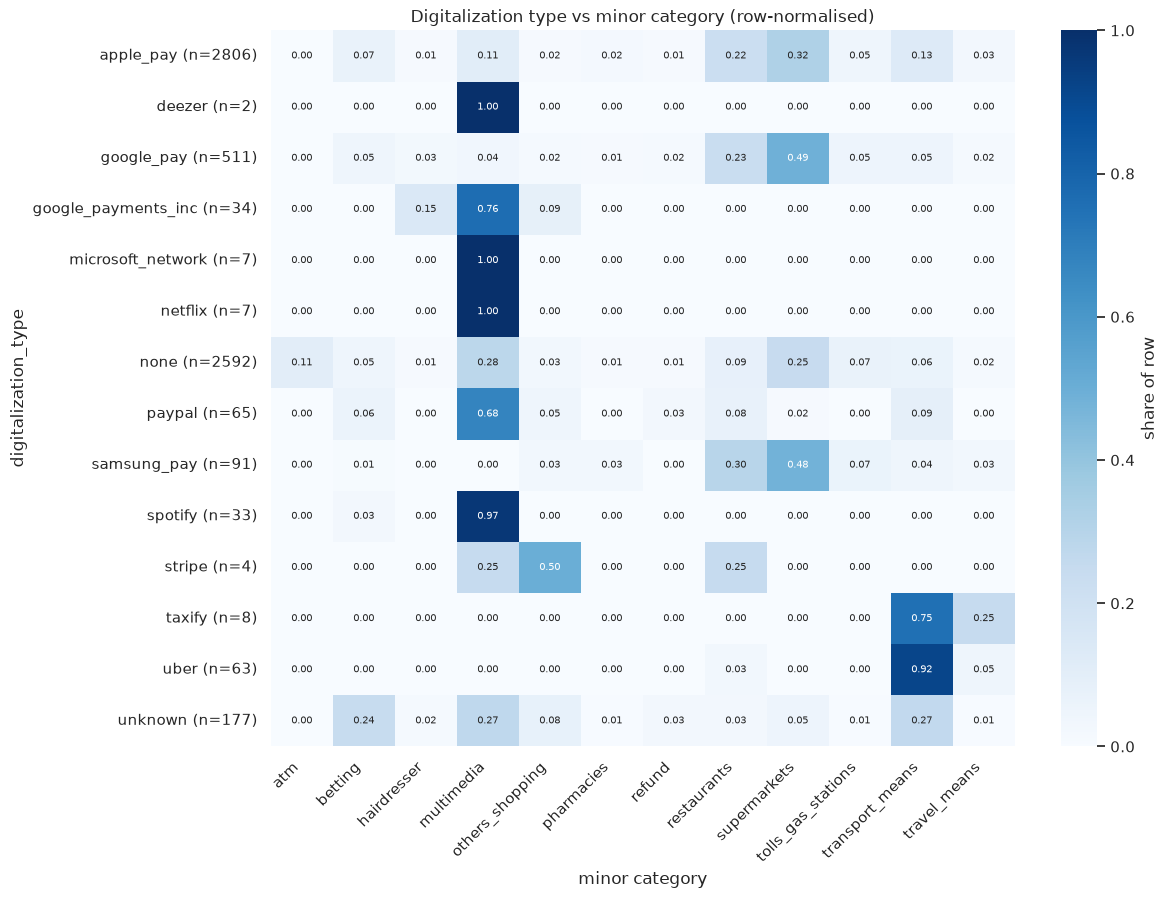

In [10]:
def heat(col, name, title):
    ct = pd.crosstab(dtrain[col], dtrain[TARGET], normalize="index")
    n = dtrain[col].value_counts()
    ct.index = [f"{i} (n={n[i]})" for i in ct.index]
    plt.figure(figsize=(12, 0.45 * len(ct) + 3))
    sns.heatmap(ct, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "share of row"})
    plt.title(title); plt.xlabel("minor category"); plt.ylabel(col); plt.xticks(rotation=45, ha="right")
    save(name)
heat("merchant_pan_entry_method", "entry_method", "Entry method vs minor category (row-normalised)")
heat("digitalization_type", "digitalization", "Digitalization type vs minor category (row-normalised)")

In [11]:
print("P(digitalization_type | class), column-normalised:"); display(pd.crosstab(dtrain["digitalization_type"], dtrain[TARGET], normalize="columns").round(2))
print("share of 'none' digitalization by class:"); print(dtrain["digitalization_type"].eq("none").groupby(dtrain[TARGET]).mean().round(2).sort_values(ascending=False).to_string())
print("pfm_recurring_frequency by class (counts):"); display(pd.crosstab(dtrain[TARGET], dtrain["pfm_recurring_frequency"]))
print("share with fees>0 by class:"); print((dtrain["fees"] > 0).groupby(dtrain[TARGET]).mean().round(3).to_string())
for c in CAT_COLS: print(c, "cardinality:", dtrain[c].nunique())
from sklearn.metrics import mutual_info_score
rng = np.random.default_rng(0); y = dtrain[TARGET].to_numpy()
rows = []
for c in ["merchant_pan_entry_method", "digitalization_type", "status", "pfm_recurring_frequency", "card_name"]:
    mi = mutual_info_score(dtrain[c], y); chance = np.mean([mutual_info_score(dtrain[c], rng.permutation(y)) for _ in range(20)])
    rows.append((c, dtrain[c].nunique(), mi, chance, mi / chance))
print("mutual information with the minor label vs a 20-permutation chance baseline (nats):")
display(pd.DataFrame(rows, columns=["column", "cardinality", "MI", "chance MI", "ratio"]).round(4).set_index("column"))

P(digitalization_type | class), column-normalised:


minor_category,atm,betting,hairdresser,multimedia,others_shopping,pharmacies,refund,restaurants,supermarkets,tolls_gas_stations,transport_means,travel_means
digitalization_type,,,,,,,,,,,,
apple_pay,0.0,0.51,0.39,0.26,0.26,0.54,0.42,0.62,0.49,0.38,0.54,0.58
deezer,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
google_pay,0.0,0.06,0.14,0.01,0.05,0.07,0.10,0.12,0.14,0.08,0.04,0.06
google_payments_inc,0.0,0.00,0.05,0.02,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00
microsoft_network,0.0,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
netflix,0.0,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
none,1.0,0.32,0.38,0.59,0.53,0.35,0.41,0.22,0.35,0.53,0.24,0.30
paypal,0.0,0.01,0.00,0.04,0.02,0.00,0.02,0.00,0.00,0.00,0.01,0.00
samsung_pay,0.0,0.00,0.00,0.00,0.02,0.03,0.00,0.03,0.02,0.02,0.01,0.02


share of 'none' digitalization by class:
minor_category
atm                   1.00
multimedia            0.59
tolls_gas_stations    0.53
others_shopping       0.53
refund                0.41
hairdresser           0.38
supermarkets          0.35
pharmacies            0.35
betting               0.32
travel_means          0.30
transport_means       0.24
restaurants           0.22
pfm_recurring_frequency by class (counts):


pfm_recurring_frequency,monthly,none
minor_category,,
atm,0,275
betting,5,406
hairdresser,0,92
multimedia,159,1073
others_shopping,4,161
pharmacies,0,102
refund,4,89
restaurants,1,1006
supermarkets,0,1851


share with fees>0 by class:
minor_category
atm                   0.004
betting               0.007
hairdresser           0.011
multimedia            0.006
others_shopping       0.006
pharmacies            0.000
refund                0.011
restaurants           0.011
supermarkets          0.010
tolls_gas_stations    0.011
transport_means       0.010
travel_means          0.007
digitalization_type cardinality: 14
merchant_pan_entry_method cardinality: 6
pfm_recurring_frequency cardinality: 2
status cardinality: 2


mutual information with the minor label vs a 20-permutation chance baseline (nats):


,cardinality,MI,chance MI,ratio
column,,,,
merchant_pan_entry_method,6,0.6311,0.0040,157.1705
digitalization_type,14,0.1666,0.0101,16.4661
status,2,0.0759,0.0010,79.6904
pfm_recurring_frequency,2,0.0369,0.0009,39.9911
card_name,30,0.0286,0.0261,1.0965


## 7. Time
Inspect volume and time-of-day patterns, then apply the project's temporal split and quantify what share of test rows have a normalised title that already appears in training.

date range: 2026-03-13 00:03:44+00:00 -> 2026-06-10 23:59:49+00:00 | NaT: 0
partial weeks (edges): [('2026-03-15', 255), ('2026-06-14', 306)]
complete weeks: 12 | median / min / max per week: 620.0 591 671


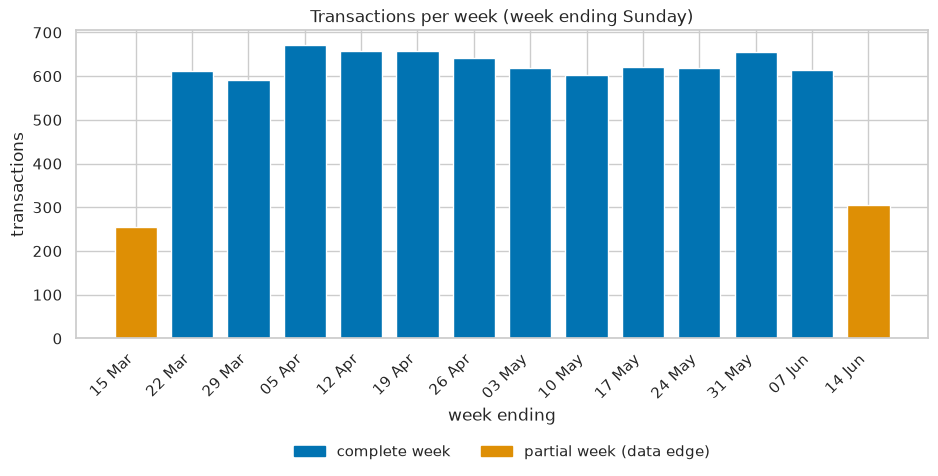

In [12]:
t = df["created_at"].dt.tz_localize(None)
per = t.dt.to_period("W-SUN"); wk = per.value_counts().sort_index()
starts, ends = wk.index.start_time, wk.index.end_time.normalize()
partial = (starts < t.min().normalize()) | (ends > t.max().normalize())
print("date range:", df["created_at"].min(), "->", df["created_at"].max(), "| NaT:", df["created_at"].isna().sum())
print("partial weeks (edges):", [(str(a.date()), int(n)) for a, n in zip(ends[partial], wk.values[partial])])
cw = wk[~partial]; print("complete weeks:", len(cw), "| median / min / max per week:", cw.median(), cw.min(), cw.max())
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(wk)), wk.values, color=[ORANGE if p else BLUE for p in partial], width=0.75)
ax.set_xticks(range(len(wk))); ax.set_xticklabels([e.strftime("%d %b") for e in ends], rotation=45, ha="right")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="complete week"), Patch(color=ORANGE, label="partial week (data edge)")], loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)
ax.set(title="Transactions per week (week ending Sunday)", xlabel="week ending", ylabel="transactions"); save("volume_over_time")

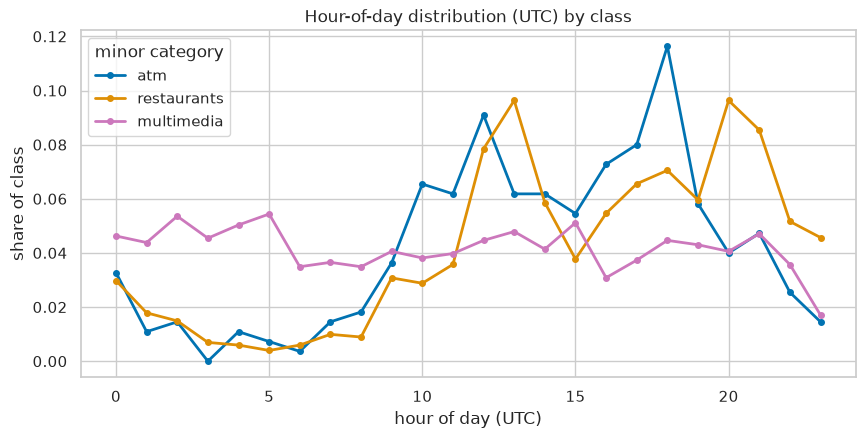

In [13]:
h = dtrain.assign(hour=dtrain["created_at"].dt.hour)
sel = ["atm", "restaurants", "multimedia"]
plt.figure(figsize=(10, 4.5))
for c, col in zip(sel, [PAL[0], PAL[1], PAL[4]]):
    s = h[h[TARGET] == c]["hour"].value_counts(normalize=True).sort_index().reindex(range(24), fill_value=0)
    plt.plot(s.index, s.values, marker="o", ms=4, lw=2, color=col, label=c)
plt.title("Hour-of-day distribution (UTC) by class"); plt.xlabel("hour of day (UTC)"); plt.ylabel("share of class"); plt.legend(title="minor category")
save("hour_by_class")

In [14]:
train, test = temporal_split(df)
cut = test["created_at"].min()
print("raw EDA split: cut date:", cut, "| train:", len(train), "| test:", len(test))
print("deduplicated split (the one the model uses): test from", dtest["created_at"].min(), "| train:", len(dtrain), "| test:", len(dtest))
test = test.assign(text_norm=test["title"].map(normalise_merchant)); train = train.assign(text_norm=train["title"].map(normalise_merchant))
seen = test["text_norm"].isin(set(train["text_norm"]))
print(f"[raw split] share of test rows with normalised title seen in train: {seen.mean():.4f} | seen {int(seen.sum())}/{len(test)} | unseen rows: {(~seen).sum()}")
_tn = dtrain["title"].map(normalise_merchant); _sn = dtest["title"].map(normalise_merchant).isin(set(_tn))
print(f"[deduplicated split, used by the model] seen {int(_sn.sum())}/{len(dtest)} = {_sn.mean():.4f} | unseen {int((~_sn).sum())} = {1 - _sn.mean():.4f}")
print("unseen test titles (unique):", test.loc[~seen, "text_norm"].nunique())
print("label distribution of unseen-merchant test rows:"); print(test.loc[~seen, TARGET].value_counts().to_string())
cmp = pd.DataFrame({"train": train[TARGET].value_counts(normalize=True), "test": test[TARGET].value_counts(normalize=True)}).round(3)
display(cmp)
print("classes absent from train:", set(df[TARGET]) - set(train[TARGET]), "| absent from test:", set(df[TARGET]) - set(test[TARGET]))

raw EDA split: cut date: 2026-05-24 10:04:31+00:00 | train: 6496 | test: 1625
deduplicated split (the one the model uses): test from 2026-05-24 11:07:07+00:00 | train: 6400 | test: 1601
[raw split] share of test rows with normalised title seen in train: 0.9520 | seen 1547/1625 | unseen rows: 78
[deduplicated split, used by the model] seen 1523/1601 = 0.9513 | unseen 78 = 0.0487
unseen test titles (unique): 70
label distribution of unseen-merchant test rows:
minor_category
restaurants           17
pharmacies            16
supermarkets          14
transport_means       11
tolls_gas_stations     6
betting                4
refund                 3
multimedia             3
atm                    2
travel_means           1
others_shopping        1


,train,test
minor_category,,
atm,0.043,0.047
betting,0.064,0.054
hairdresser,0.014,0.016
multimedia,0.193,0.190
others_shopping,0.026,0.018
pharmacies,0.016,0.016
refund,0.015,0.017
restaurants,0.158,0.159
supermarkets,0.289,0.306


classes absent from train: set() | absent from test: set()


In [15]:
from scipy.stats import chi2_contingency
dn = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow = dtrain["created_at"].dt.dayofweek.map(dict(enumerate(dn)))
ct = pd.crosstab(dow, dtrain[TARGET]).reindex(dn)
print("share of each class's deduplicated training rows by weekday (columns sum to 1):"); display(pd.crosstab(dow, dtrain[TARGET], normalize="columns").reindex(dn).round(2))
print("overall weekday share:", (dow.value_counts(normalize=True).reindex(dn)).round(3).to_dict())
chi2, pval, _, _ = chi2_contingency(ct); print(f"chi-square test of weekday x class independence: p = {pval:.3g}")
print("classes with the largest weekend share:", dtrain.assign(we=dtrain["created_at"].dt.dayofweek >= 5).groupby(TARGET)["we"].mean().round(3).sort_values(ascending=False).head(4).to_dict())

share of each class's deduplicated training rows by weekday (columns sum to 1):


minor_category,atm,betting,hairdresser,multimedia,others_shopping,pharmacies,refund,restaurants,supermarkets,tolls_gas_stations,transport_means,travel_means
created_at,,,,,,,,,,,,
Mon,0.16,0.16,0.10,0.17,0.16,0.16,0.16,0.12,0.17,0.16,0.13,0.17
Tue,0.15,0.19,0.13,0.14,0.19,0.16,0.10,0.14,0.16,0.12,0.16,0.13
Wed,0.13,0.11,0.13,0.16,0.09,0.17,0.16,0.12,0.14,0.13,0.11,0.13
Thu,0.15,0.14,0.23,0.12,0.10,0.09,0.14,0.13,0.12,0.13,0.12,0.12
Fri,0.15,0.13,0.15,0.20,0.22,0.21,0.16,0.16,0.15,0.14,0.15,0.19
Sat,0.14,0.15,0.18,0.11,0.13,0.19,0.16,0.18,0.16,0.16,0.19,0.16
Sun,0.12,0.11,0.08,0.11,0.10,0.04,0.12,0.14,0.09,0.16,0.14,0.11


overall weekday share: {'Mon': 0.154, 'Tue': 0.152, 'Wed': 0.133, 'Thu': 0.126, 'Fri': 0.164, 'Sat': 0.155, 'Sun': 0.115}
chi-square test of weekday x class independence: p = 5.82e-08
classes with the largest weekend share: {'transport_means': 0.335, 'tolls_gas_stations': 0.324, 'restaurants': 0.319, 'refund': 0.28}


## 8. Identifiers & leakage
Check whether identifier columns would let a model memorise rather than generalise, and document why they are excluded.

In [16]:
tr_m, te_m = set(train["member_id"]), set(test["member_id"])
print("members:", df["member_id"].nunique(), "| test members seen in train:", round(len(te_m & tr_m) / len(te_m), 3),
      "| test rows from seen members:", round(test["member_id"].isin(tr_m).mean(), 3))
print("transactions per member (median / max):", df.groupby("member_id").size().median(), df.groupby("member_id").size().max())
print("merchant_id cardinality:", df["merchant_id"].nunique(), "| cleaned merchant_name cardinality (959 non-null + empty):", df["merchant_name"].nunique(), "| normalised title:", df["text_norm"].nunique())
print("merchant_ids per normalised title (max):", df.groupby("text_norm")["merchant_id"].nunique().max())
print("normalised titles per merchant_id (max):", df.groupby("merchant_id")["text_norm"].nunique().max())
print("unique transaction_id:", df["transaction_id"].nunique(), "| unique ref_id:", df["ref_id"].nunique(), "| rows:", len(df))
lab = df.groupby("merchant_id")[TARGET].nunique()
print("merchant_ids with >1 label:", (lab > 1).sum())

members: 2395 | test members seen in train: 0.913 | test rows from seen members: 0.909
transactions per member (median / max): 3.0 11
merchant_id cardinality: 2789 | cleaned merchant_name cardinality (959 non-null + empty): 960 | normalised title: 875
merchant_ids per normalised title (max): 32
normalised titles per merchant_id (max): 1
unique transaction_id: 8121 | unique ref_id: 8001 | rows: 8121
merchant_ids with >1 label: 227


**Excluded columns.** `member_id` and `member_name` identify people (PII; a user-level memoriser would not transfer to new users), `transaction_id` is unique per row and `ref_id` has 8,001 unique values over 8,121 rows (unique only after deduplication); neither carries signal and both are pure memorisation risk, and `merchant_id` is a near-duplicate of the merchant title that is not available for unseen merchants and adds nothing beyond the text. `amount_currency` and `card_type` are constant.

## 9. Conclusions → modelling decisions

**Rulings carried into modelling**

Feature-selection diagnostics are computed on the deduplicated training period (6,400 rows); the full frame, including the holdout, was inspected during exploration, so the holdout is not pristine; model and hyper-parameter selection nevertheless used only cross-validation on the training period.

- **(a) Deduplicate before splitting.** 120 rows are exact repeats on every column except `transaction_id` (`ref_id` has 8,001 unique values for 8,121 rows; 8,001 rows remain after dropping them). Inside the training period, 87 of 101 duplicate groups would straddle folds under StratifiedKFold(5, shuffle, random_state=42), so CV on the raw rows would leak; the temporal split has no cross-split duplicate leakage (0 groups span train and test), but the test period holds its own duplicate copies, so it is deduplicated too.
- **Predict minor, derive major; refund guard.** Minor-to-major is a strict function (max 1 major per minor); refund (123 rows, null major) is exactly `status == "refunded"` and exactly `amount_value > 0`. The model still learns all 12 classes, refund included; the deterministic refund guard then overrides the model's probabilities after inference.
- **Title is the main feature, as character n-grams on the normalised title.** Normalisation merges 38 groups of raw spellings (960 raw titles to 875), but McDonald's alone stays split over 14 normalised spellings (`mc donald s` 192, `mcdonald s` 68, `mac donald s` 56, ...), and 70 test titles (78 rows, 4.8%) are unseen; sub-word features handle both. 31 titles normalise to the empty string (digit-only strings, 30 of them ATM); they get no text features and are classified from the structured features alone.
- **(c) In-sample normalised-title agreement is a diagnostic, not an upper bound.** Majority-label agreement is 0.9468 on all rows, 0.9612 once the refund rule is applied first (315 suspected inconsistencies), and 0.9614 on the deduplicated frame (309 of 8,001). It uses only the title in-sample, so a model using amount, entry method and digitalization may beat it; the disagreements (145 of 875 titles carry more than one label, covering 73.1% of rows) are suspected inconsistencies, not verified errors.
- **Established signals kept (deduplicated training period, MI vs 20-permutation chance baseline, nats):** title text; `merchant_pan_entry_method` (0.631 vs 0.004, ratio 157); `digitalization_type` (0.167 vs 0.010, ratio 16; `uber` 92% transport_means, `spotify` 97% multimedia; `none` is 100% of ATM but also 59% of multimedia, 53% of tolls and 53% of others_shopping); `status` (0.076 vs 0.001, ratio 80); `pfm_recurring_frequency` (0.037 vs 0.001, ratio 40; null on 97.3% of raw rows, filled with `none`); and the refund rule.
- **(b) Drop `card_name`.** Its MI with the label is 0.0286 nats against a 0.0261 permutation baseline (ratio 1.10, 30 levels), i.e. indistinguishable from chance, while the four retained columns sit 16x to 157x above chance. `fees` > 0 on at most 1.1% of training rows in any class, so it is a weak signal; `fees_log` and `has_fees` are nevertheless kept as cheap model features (the pipeline does not drop them).
- **(d) Amounts: log1p(|amount|), no capping, sign kept separately.** Extremes are disclosed, not clipped: debits reach -399,180.56 and credits 76,098.48 (-222,158.92 is the 0.1% quantile of signed debit amounts, and +222,158.92 is the 99.9% quantile of |amount| over debit rows, against a median debit of -10.89; the notebook counts the rows with |amount| >= 10,000 and lists them by class), the 10 largest absolute amounts all carry restaurant-chain titles (9 of 10 labelled restaurants), and 5 ATM rows have amount 0. These values look synthetic; the log transform tames them.
- **Candidate features to validate in CV (not yet established):** (i) day of week, since weekday x class is not independent in the deduplicated training period (chi-square p = 5.8e-08; e.g. pharmacies 3.9% on Sunday vs 11.5% overall, transport_means 33.5% and restaurants 31.9% on weekends) but effects are modest; (ii) **(e)** a round-amount indicator (|amount| > 0 and divisible by 10): 99.3% of ATM rows and 28.7% of betting rows are round versus at most 8.7% in any other class (training period). It is shipped in the pipeline as `is_round_amount`. It does not separate the 4 non-ATM `RETRAIT DAB` rows from the 109 ATM ones (full frame: 109 atm / 4 transport_means; 79 / 3 in the deduplicated training period; the 4 have amounts of -40 to -310, all `chip`, `none` digitalization), so it must earn its place in CV.
- **(f) Availability at transaction time is an assumption.** `status` and `pfm_recurring_frequency` are used because the test's data dictionary lists them as available at transaction time; if `status` were a later update, refund would have to be predicted from text alone, and the `none` fill for recurrence is not documented semantics.
- **Temporal split, not random.** Data spans 2026-03-13 to 2026-06-10. The raw EDA split (cut 2026-05-24 10:04, 6,496 train / 1,625 test, all 12 classes in both) differs from the final deduplicated split (6,400 train / 1,601 test, test from 2026-05-24 11:07); the model uses the deduplicated one. Complete weeks hold 591 to 671 transactions (median 620; the two edge weeks of 255 and 306 are partial and not a real drop). 95.2% of test rows have a normalised title that appears in training on the raw split; 95.1% (1,523/1,601) on the deduplicated split the model uses (4.9% unseen).
- **Metrics.** The largest class is 29.3% and the max/min imbalance is 20.1x, so report macro-F1 and per-class recall alongside accuracy, for minor and derived major.
- **Excluded columns.** `member_id` (2,395 members, 91.3% of test members already seen in train), `member_name`, `ref_id`, `transaction_id`, `merchant_id` (2,789 values, 227 with mixed labels, unavailable for new merchants) are identifiers or PII; `amount_currency` and `card_type` are constant.
